# Part 1: Exploratory data analysis

What in the raw data matters for building the best model. Each section shows one finding and what it implies for cleaning (part 2) and for transforms and models (part 3). Numbers quoted from experiments outside this notebook come from the scratch study summarized in `docs/eda_findings.md`, which also lists the cleaning rule of every feature.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from p1 import eda
from p1.data import load_raw

eda.use_style()
ds = load_raw()
x, y, names = ds.x_train, ds.y_train, ds.feature_names


def col(name, data=x):
    """Column `name` of `data` (the training features by default)."""
    return data[:, names.index(name)]

## 1. The task in numbers

In [2]:
p = y.mean()
eda.print_table(
    ["", "value"],
    [
        ("training rows", len(y)),
        ("test rows", len(ds.x_test)),
        ("features", len(names)),
        ("positive rate (MICHD)", f"{p:.1%}"),
        ("accuracy of always predicting 0", f"{1 - p:.1%}"),
        ("F1 of always predicting 1", f"{2 * p / (1 + p):.3f}"),
    ],
)

                                  value
training rows                    328135
test rows                        109379
features                            321
positive rate (MICHD)              8.8%
accuracy of always predicting 0   91.2%
F1 of always predicting 1         0.162


Only 8.8% of respondents are positive. Accuracy is useless as a guide (91% with no model at all), and F1 depends on how many people the model flags, so the decision threshold must be tuned rather than left at 0.5 (section 9). Any model must beat F1 = 0.162, the score of flagging everyone.

## 2. Missing values are frequent, structured and informative

NaN cells: 45%, complete rows: 0


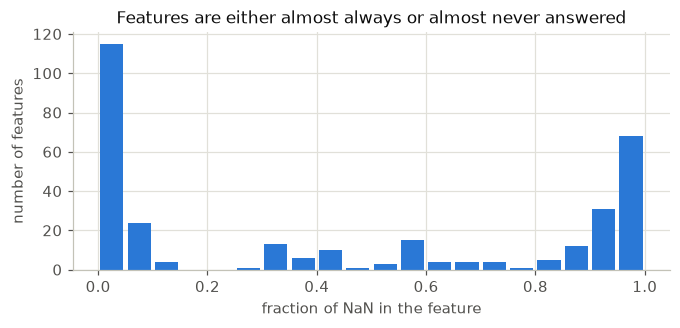

feature   NaN  pos. rate if NaN  if answered  NaN means
BPMEDS    60%              3.8%        16.3%  no high blood pressure
TOLDHI2   13%              2.5%         9.8%  cholesterol never checked
POORHLTH  49%              6.2%        11.3%  no day of poor health
DIABAGE2  87%              6.9%        22.1%  not diabetic
_FLSHOT6  64%              4.6%        16.4%  younger than 65
CTELENUM  42%              6.2%        10.7%  interviewed by cell phone


In [3]:
nan_train, nan_test = eda.missing_fraction(x), eda.missing_fraction(ds.x_test)
nan_cells = np.isnan(x)
print(
    f"NaN cells: {nan_cells.mean():.0%}, complete rows: {(~nan_cells.any(axis=1)).sum()}"
)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(nan_train, bins=np.linspace(0, 1, 21), color=eda.BLUE, rwidth=0.85)
ax.set(
    xlabel="fraction of NaN in the feature",
    ylabel="number of features",
    title="Features are either almost always or almost never answered",
)
eda.save_figure(fig, "eda_missing")
plt.show()

skipped_when = {
    "BPMEDS": "no high blood pressure",
    "TOLDHI2": "cholesterol never checked",
    "POORHLTH": "no day of poor health",
    "DIABAGE2": "not diabetic",
    "_FLSHOT6": "younger than 65",
    "CTELENUM": "interviewed by cell phone",
}
rows = []
for name, meaning in skipped_when.items():
    nan = np.isnan(col(name))
    rows.append(
        (
            name,
            f"{nan.mean():.0%}",
            f"{y[nan].mean():.1%}",
            f"{y[~nan].mean():.1%}",
            meaning,
        )
    )
eda.print_table(
    ["feature", "NaN", "pos. rate if NaN", "if answered", "NaN means"], rows, "lrrrl"
)

- There is no complete row and 45% of all cells are NaN, so every model needs a strategy for NaNs. Most features are answered by nearly everyone (core questions) or by almost no one: about 100 questions come from optional modules asked in a few states only.
- Most NaNs are not random. The survey skips questions that do not apply, so a NaN is itself an answer: a NaN in `BPMEDS` means "no high blood pressure", with 3.8% positives against 16.3% for those asked.
- Consequences: keep NaN as its own category or add a NaN indicator, instead of only filling it with a median. When a skipped numeric answer has an obvious value, use it (0 days of poor health, 0 drinks). Do not drop features just because they are mostly NaN: dropping the features with more than 90% NaN lowered F1 from 0.440 to 0.430 in our tests, mostly because of the leak of section 4.

## 3. Answers are codes, not quantities

In [4]:
examples = {
    "CVDSTRK3": {1: "yes", 2: "no", 7: "don't know", 9: "refused"},
    "PHYSHLTH": {
        88: "none",
        1: "1 day",
        15: "15 days",
        30: "30 days",
        77: "don't know",
        99: "refused",
    },
    "INCOME2": {
        1: "< $10k",
        4: "$20-25k",
        8: ">= $75k",
        77: "don't know",
        99: "refused",
    },
}
titles = [
    "ever had a stroke",
    "days of poor physical health in the last 30",
    "household income bracket",
]
for (name, codes), title in zip(examples.items(), titles):
    values, counts, rates = eda.positive_rate_by_value(col(name), y)
    print(f"{name}: {title}")
    rows = [
        (c, meaning, counts[values == c][0], f"{rates[values == c][0]:.1%}")
        for c, meaning in codes.items()
    ]
    eda.print_table(["code", "meaning", "rows", "positive rate"], rows, "rlrr")
    print()

CVDSTRK3: ever had a stroke
code  meaning       rows  positive rate
   1  yes          13366          37.1%
   2  no          314032           7.6%
   7  don't know     717          31.7%
   9  refused         20          25.0%

PHYSHLTH: days of poor physical health in the last 30
code  meaning       rows  positive rate
  88  none        204264           5.9%
   1  1 day        13676           5.0%
  15  15 days       6150          18.7%
  30  30 days      25233          22.9%
  77  don't know    5587          16.3%
  99  refused       1520          15.9%

INCOME2: household income bracket
code  meaning      rows  positive rate
   1  < $10k      13549          13.4%
   4  $20-25k     24059          12.0%
   8  >= $75k     86314           4.9%
  77  don't know  25917          10.3%
  99  refused     30206           8.7%



BRFSS stores answers as codes: 7, 77, 777 and 7777 mean "don't know", 9, 99, 999 and 9999 "refused", 88 and 888 "none", 555 "never". Some questions also pack units into the number: `ALCDAY5` is 1xx for days per week and 2xx for days per month, and `WEIGHT2` is in pounds unless it starts with 9 (kilograms). Read as numbers, the codes are badly wrong: "none" (88) becomes the largest value of `PHYSHLTH`, and "refused" (99) the richest income bracket.

- "Don't know" is neither yes nor no. For diseases it is close to "yes" (31.7% positives for strokes, against 37.1% for yes and 7.6% for no), so turning it into NaN and then into the median ("no") loses information. One-hot encoding keeps every code as its own column, without needing the codebook.
- Numeric questions need fixed rules before they can be used as numbers: 88 → 0, "don't know" and "refused" → NaN, and unit conversions. The variables computed by the CDC (names starting or ending with `_`) already do this for weight, height, BMI, alcohol, fruit and vegetables and physical activity, so the raw mixed-unit versions can be dropped.

## 4. A label leak: `HAREHAB1`

In [5]:
answered = ~np.isnan(col("HAREHAB1"))
print(
    f"train: {answered.sum()} answered HAREHAB1, {y[answered].mean():.0%} of them positive"
)
answered_test = ~np.isnan(col("HAREHAB1", ds.x_test))
print(f"test:  {answered_test.sum()} answered HAREHAB1")

train: 773 answered HAREHAB1, 100% of them positive
test:  238 answered HAREHAB1


`HAREHAB1` ("did you go to cardiac rehabilitation after your heart attack?") is asked only to people who reported a heart attack, which is part of the definition of MICHD. All 773 training respondents who answered it are positive, so the 238 test respondents who answered it are certain positives (about 2.5% of the expected test positives). A model learns this on its own if the feature is kept with a NaN indicator or one-hot encoded; it must not be removed by a "too many NaNs" filter. `STREHAB1` follows the same logic for strokes, which are not part of MICHD (36% positives).

## 5. Which features carry signal

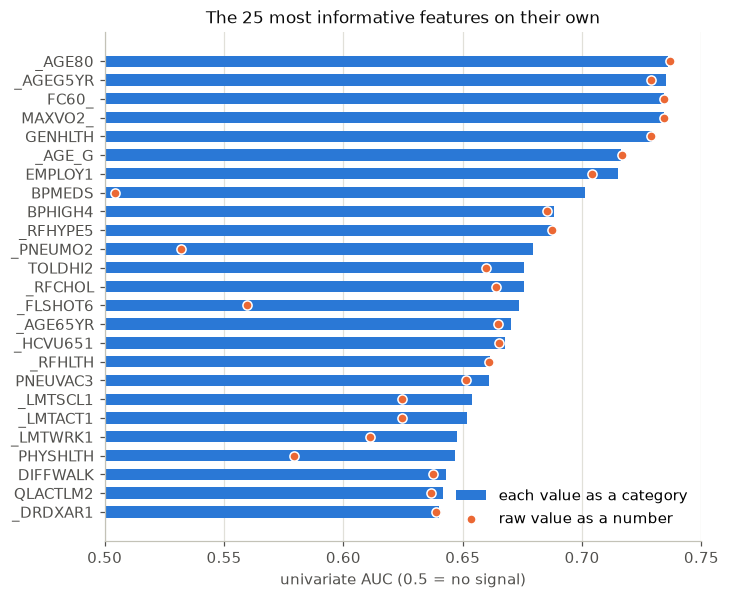

features with no signal (AUC < 0.505): 57
most signal lost as raw numbers: BPMEDS 0.70 -> 0.50, _PNEUMO2 0.68 -> 0.53, MARITAL 0.62 -> 0.50, _FLSHOT6 0.67 -> 0.56, DIABAGE2 0.61 -> 0.51, JOINPAIN 0.64 -> 0.55


In [6]:
encoded_auc, raw_auc = eda.univariate_auc(x, y)
top = np.argsort(-encoded_auc)[:25][::-1]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(
    range(25),
    encoded_auc[top] - 0.5,
    left=0.5,
    height=0.6,
    color=eda.BLUE,
    label="each value as a category",
)
ax.scatter(
    raw_auc[top],
    range(25),
    s=36,
    color=eda.ORANGE,
    edgecolor="white",
    zorder=3,
    label="raw value as a number",
)
ax.set_yticks(range(25), [names[j] for j in top])
ax.set(
    xlim=(0.5, 0.75),
    xlabel="univariate AUC (0.5 = no signal)",
    title="The 25 most informative features on their own",
)
ax.grid(axis="y", visible=False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right")
eda.save_figure(fig, "eda_univariate_auc")
plt.show()

print(f"features with no signal (AUC < 0.505): {(encoded_auc < 0.505).sum()}")
loss = np.argsort(raw_auc - encoded_auc)[:6]
print(
    "most signal lost as raw numbers:",
    ", ".join(f"{names[j]} {encoded_auc[j]:.2f} -> {raw_auc[j]:.2f}" for j in loss),
)

Each feature is scored by how well it alone separates the classes (AUC, 0.5 = no signal). The bar treats each value (or quantile bin) as a category scored by its positive rate, learned on the other half of the rows; the dot uses the raw value as a number, which is what a linear model sees without encoding.

- The strongest signals are classic cardiovascular risk factors: age (`_AGE80`, `_AGEG5YR`, and `FC60_`/`MAXVO2_`, which are computed from age), general health, employment (retired or unable to work), blood pressure, cholesterol, arthritis and activity limitations.
- Where the dot falls far left of the bar, the raw number hides the signal: skip-logic NaNs (`BPMEDS`, `_PNEUMO2`), codes (`PHYSHLTH`) and nominal answers without order (`MARITAL`). These need one-hot encoding or recoding.
- About 60 features carry no signal at all, mostly from optional modules.
- A univariate ranking is a poor way to select features: rare but strong conditions (stroke, kidney disease) and sex rank low alone yet matter in a model. Keeping only the 60 best features lowered F1 from 0.440 to 0.416 in our tests.

## 6. Shape of the main effects

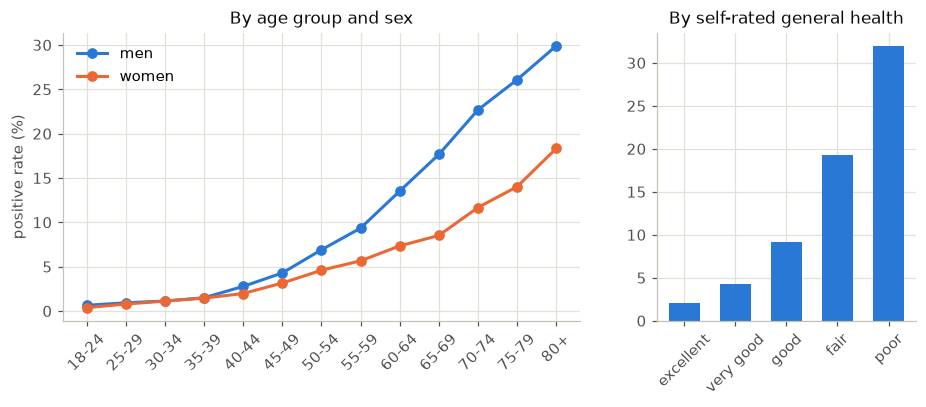

In [7]:
age_groups = [
    "18-24",
    "25-29",
    "30-34",
    "35-39",
    "40-44",
    "45-49",
    "50-54",
    "55-59",
    "60-64",
    "65-69",
    "70-74",
    "75-79",
    "80+",
]
health = ["excellent", "very good", "good", "fair", "poor"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), width_ratios=[2, 1])
for sex, label, color in [(1, "men", eda.BLUE), (2, "women", eda.ORANGE)]:
    is_sex = col("SEX") == sex
    values, _, rates = eda.positive_rate_by_value(col("_AGEG5YR")[is_sex], y[is_sex])
    left.plot(values[:13], 100 * rates[:13], marker="o", ms=6, color=color, label=label)
left.set_xticks(range(1, 14), age_groups, rotation=45)
left.set(ylabel="positive rate (%)", title="By age group and sex")
left.legend()
values, _, rates = eda.positive_rate_by_value(col("GENHLTH"), y)
right.bar(health, 100 * rates[:5], width=0.6, color=eda.BLUE)
right.tick_params(axis="x", rotation=45)
right.set(title="By self-rated general health")
eda.save_figure(fig, "eda_age_health")
plt.show()

- Risk rises steeply with age, from 0.5% under 25 to 22% over 80, and the rise is not linear: it accelerates after 40.
- The sex gap depends on age: men and women have the same risk below 40, then men have 1.4 to 2 times the risk of women. This is an age × sex interaction, which an additive model cannot fit exactly. In our tests, products of the top 20 features improved F1 by only 0.002, so interactions are a small gain at best.
- General health is a clean gradient from 2% (excellent) to 32% (poor). Ordered answers have monotone but unevenly spaced effects: one-hot encoding, or binning of continuous variables, lets a linear model fit any such shape.

## 7. Identifiers and redundant columns

In [8]:
print("identical columns:", eda.duplicate_columns(x, names))
pairs = eda.correlated_pairs(x, names)
print(f"{len(pairs)} pairs with |correlation| > 0.95, the first ones:")
for r, a, b in pairs[:12]:
    print(f"  {a:>9} ~ {b:<9} {r:.3f}")

# About the survey, not the respondent: ids, interview dates, strata, weights.
survey_design = [
    "SEQNO",
    "_PSU",
    "FMONTH",
    "IDATE",
    "IMONTH",
    "IDAY",
    "IYEAR",
    "_STSTR",
    "_STRWT",
    "_RAWRAKE",
    "_WT2RAKE",
    "_LLCPWT",
    "_CLLCPWT",
    "_DUALCOR",
]

identical columns: [('SEQNO', '_PSU'), ('CTELNUM1', 'CELLFON2'), ('_CRACE1', '_CPRACE')]


46 pairs with |correlation| > 0.95, the first ones:
      SEQNO ~ _PSU      1.000
    _CRACE1 ~ _CPRACE   1.000
   HAVARTH3 ~ _DRDXAR1  1.000
     _STATE ~ _STSTR    1.000
      IDATE ~ IMONTH    1.000
      HTIN4 ~ HTM4      1.000
   SMOKDAY2 ~ _SMOKER3  0.999
    _PRACE1 ~ _MRACE1   0.999
    MAXVO2_ ~ FC60_     0.998
   _VEGRESP ~ _VEGETEX  0.998
   EXERHMM2 ~ PADUR2_   0.997
   EXERHMM1 ~ PADUR1_   0.996


- Three pairs of columns are exact copies, and 46 pairs are correlated above 0.95: mostly a raw answer and the CDC variable computed from it (`HAVARTH3`/`_DRDXAR1`, `SMOKDAY2`/`_SMOKER3`, the four age variables, ...).
- 14 columns describe the survey rather than the person: record ids (`SEQNO` = `_PSU`), interview dates, sampling strata and weights. They added nothing in our tests (F1 0.4392 with them, 0.4400 without) and can be dropped in part 2.
- Exact copies make XᵀX singular, and so does a one-hot design with a column for every level (293 zero eigenvalues in our encoding): plain least squares with `np.linalg.solve` fails. Normal-equation models need ridge (λ > 0) or one dropped level per one-hot group. Gradient methods and ridge are not affected by near-duplicates.

## 8. Train and test come from the same distribution

In [9]:
share_train = np.bincount(col("_STATE").astype(int), minlength=80) / len(x)
share_test = np.bincount(col("_STATE", ds.x_test).astype(int), minlength=80) / len(
    ds.x_test
)
nan_gap = np.abs(nan_train - nan_test).max()
state_gap = np.abs(share_train - share_test).max()
print(f"largest train-test gap in the NaN rate of a feature: {nan_gap:.4f}")
print(f"largest train-test gap in the share of a state:      {state_gap:.4f}")
print(f"AUC of the row index: {eda.roc_auc(np.arange(len(y), dtype=float), y):.3f}")

largest train-test gap in the NaN rate of a feature: 0.0040
largest train-test gap in the share of a state:      0.0013
AUC of the row index: 0.503


Train and test look like a random split of the same survey: NaN rates and state shares agree within 0.4 and 0.13 percentage points, and the order of the rows carries no information about the label. Shuffled k-fold cross-validation on the training set is therefore a faithful estimate of the leaderboard score. Over 5 folds, the F1 of a fixed pipeline varies by about ±0.004, so smaller differences between pipelines need a paired comparison (same folds) to be trusted.

## 9. What these findings are worth: a linear probe

features                     AUC  best F1  threshold  flagged  F1 at 0.5
raw values, NaN -> median  0.846    0.413      0.209    15.0%      0.014
one-hot (1906 columns)     0.856    0.431      0.226    12.7%      0.139


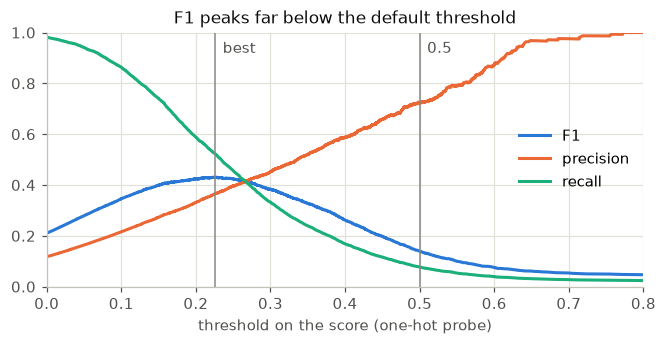

In [10]:
features = [j for j, name in enumerate(names) if name not in survey_design]
train, valid = np.split(
    np.random.default_rng(0).permutation(len(y)), [int(0.8 * len(y))]
)
x_kept = x[:, features]
x_median = np.where(np.isnan(x_kept), np.nanmedian(x_kept[train], axis=0), x_kept)
onehot_train, onehot_valid = eda.onehot_encode(x_kept[train], x_kept[valid])
scores = {
    "raw values, NaN -> median": eda.ridge_probe(
        x_median[train], y[train], x_median[valid]
    ),
    f"one-hot ({onehot_train.shape[1]} columns)": eda.ridge_probe(
        onehot_train, y[train], onehot_valid
    ),
}

rows = []
for label, score in scores.items():
    thresholds, precision, recall, f1 = eda.f1_by_threshold(score, y[valid])
    best = f1.argmax()
    flagged = score >= 0.5
    f1_half = 2 * (flagged & (y[valid] == 1)).sum() / (flagged.sum() + y[valid].sum())
    rows.append(
        (
            label,
            eda.roc_auc(score, y[valid]),
            f1[best],
            thresholds[best],
            f"{(score >= thresholds[best]).mean():.1%}",
            f1_half,
        )
    )
eda.print_table(
    ["features", "AUC", "best F1", "threshold", "flagged", "F1 at 0.5"], rows
)

fig, ax = plt.subplots(figsize=(7, 3))
for values, label, color in [
    (f1, "F1", eda.BLUE),
    (precision, "precision", eda.ORANGE),
    (recall, "recall", eda.AQUA),
]:
    ax.plot(thresholds, values, color=color, label=label)
for t, text in [(thresholds[best], "best"), (0.5, "0.5")]:
    ax.axvline(t, color=eda.MUTED, lw=1)
    ax.text(t + 0.01, 0.92, text, color=eda.INK_SOFT)
ax.set(
    xlim=(0, 0.8),
    ylim=(0, 1),
    xlabel="threshold on the score (one-hot probe)",
    title="F1 peaks far below the default threshold",
)
ax.legend(loc="center right")
eda.save_figure(fig, "eda_threshold")
plt.show()

A ridge regression is fitted on 80% of the rows and evaluated on the other 20%, once on the raw values and once after a generic one-hot encoding (every value or quantile bin, NaN included, becomes a 0/1 column).

- Encoding is worth about +0.01 AUC and +0.02 F1, with no knowledge of the codebook. With logistic regression on the same split, our tests gave a best F1 of 0.417 with raw values, 0.433 with the codes cleaned, 0.439 with NaN indicators added, and 0.440 with categorical answers one-hot encoded.
- The threshold matters more than any model choice: at 0.5 almost no one is flagged and F1 collapses. The best threshold flags about 13% of the people, more than the 8.8% who are positive. It should be chosen by cross-validation; for logistic regression it was stable across folds (0.20 ± 0.005).

## Summary for parts 2 and 3

**Part 2, fixed cleaning rules:**
- Drop the 14 survey-design columns and the 2 remaining exact copies (`CELLFON2`, `_CPRACE`).
- For numeric answers, map 88/888 to 0 and "don't know" and "refused" to NaN, and fill skipped questions with the value they imply. Use the CDC-computed versions of mixed-unit answers and drop the raw ones. The per-feature list is in `docs/eda_findings.md`.
- Keep every other feature, the sparse ones included, and above all `HAREHAB1`.

**Part 3, transforms and models:**
- One-hot encode categorical answers with "don't know", "refused" and NaN as their own columns, add NaN indicators to numeric features, then standardize.
- Logistic regression is enough: an MLP and pairwise interactions gained at most 0.002 F1 in our tests. Expect 5-fold CV F1 ≈ 0.44 ± 0.004 and AUC ≈ 0.865.
- Tune the decision threshold by cross-validation (≈ 0.2). Class weights and undersampling only move the threshold and did not do better.
- Least squares needs ridge or one dropped level per one-hot group. Compare pipelines on at least half of the rows: with a quarter of them, F1 drops by 0.013.